In [36]:
# pip install pvlib scipy pandas numpy matplotlib   (po potrebi)
import os, json
import numpy as np
import pandas as pd
import scipy.integrate as spi
from scipy.optimize import brentq
import pvlib
import matplotlib.pyplot as plt
%matplotlib inline

In [37]:
# ====================================================================================
# VHODNI PODATKI  (po meritvah spremeni samo to celico)
# ====================================================================================
EPW = "SVN_LJ_Ljubljana-Bezigrad_140150_TMYx_2007-2021.epw"   # datoteka mora biti v isti mapi kot notebook
OUTDIR = "."
SHIFT_MIN = 0            # 0 = brez zamika (zavestna odlocitev); 30 = test obcutljivosti

STATES = [0, 25, 50, 100]                                  # stopnja zatemnitve (%)
TAU_0  = {0: 0.450, 25: 0.416, 50: 0.364, 100: 0.213}      # tau_e(0 deg), junij  -> zamenjaj z decembrsko meritvijo
TAU_60 = {0: 0.370, 25: 0.353, 50: 0.320, 100: 0.219}      # tau_e(60 deg), november (D/C/B/A = 0/25/50/100 %)
THETA_CAL = 60.0         # kot druge meritve, uporabljen za kalibracijo q
VALID_ANGLE = 75         # kot za validacijo modela
TAU_VALID = {0: 0.371, 25: 0.376, 50: 0.321, 100: 0.262}   # izmerjeno pri VALID_ANGLE (november)
P_PARAM = 2              # parameter p v Karlsson-Roos (enacba 3.6)

# Stavba
WIDTH, DEPTH, HEIGHT, WWR = 25.0, 25.0, 81.0, 0.90
T_IN = 24.0
U_WALL, U_ROOF, U_GLASS = 0.25, 0.20, 1.4
ACH, RHO_AIR, CP_AIR = 0.8, 1.2, 1005.0
N_PEOPLE, Q_PERSON = 300, 200.0
P_LAMP, N_LAMPS = 7.0, 6500
OCC_FROM, OCC_TO = 7, 22          # zasedene ure (vkljucno)
PRICE_EL = 0.22                   # EUR/kWh
COP_COOL, COP_HEAT = 2.5, 3.5

# Optika
RHO_E_LIGHT, RHO_E_DARK = 0.099, 0.083     # Piccolo idr. 2018
FI = 0.258
N_GLASS = 1.5                               # lomni kolicnik za Fresnel
G_ORDINARY = 0.65                           # navadno dvoslojno steklo (baseline)
ALBEDO = 0.25                               # privzeto v pvlib
NIGHT_THRESHOLD = 1.0                       # W/m2

# Aktivacijska mesanica (delez DNEVNIH ur)
MIX = {100: 50, 50: 25, 25: 15, 0: 10}
P_MAX_W_M2 = 1.0
POWER_FRACTION = {0: 1.00, 25: 0.75, 50: 0.50, 100: 0.00, "night": 0.00}

# Ekonomija (EUR/m2)
C_GLASS_ORD, C_BLACKOUT = 400.0, 60.0
C_GLASS_SPD, C_PRIVACY = 550.0, 10.0
C_FIXED = 10000.0

In [38]:
def kr_factor(theta_deg, q, p=P_PARAM):
    z = theta_deg / 90.0
    a = 8.0
    b = 0.25 / q
    c = 1 - a - b
    alpha = 5.2 + 0.7 * q
    beta = 2.0
    gamma = (5.26 + 0.06 * p) + (0.73 + 0.14 * q)
    return 1 - a * z ** alpha - b * z ** beta - c * z ** gamma


def calibrate_q(tau0, tau60):
    """q iz razmerja tau(60)/tau(0) = f(60; q)."""
    target = tau60 / tau0
    return brentq(lambda q: kr_factor(THETA_CAL, q) - target, 0.3, 12.0)


Q = {s: calibrate_q(TAU_0[s], TAU_60[s]) for s in STATES}


def tau_theta(theta, s):
    if theta >= 90:
        return 0.0
    return TAU_0[s] * kr_factor(theta, Q[s])


def tau_dif(s):
    f = lambda phi: tau_theta(np.degrees(phi), s) * np.cos(phi) * np.sin(phi)
    return 2 * spi.quad(f, 0, np.pi / 2)[0]


TAU_DIF = {s: tau_dif(s) for s in STATES}
RHO_E = {s: RHO_E_LIGHT + (s / 100) * (RHO_E_DARK - RHO_E_LIGHT) for s in STATES}


def rho_fresnel(theta, n=N_GLASS):
    if theta >= 90:
        return 1.0
    ti = np.radians(theta)
    tt = np.arcsin(np.sin(ti) / n)
    rs = ((np.cos(ti) - n * np.cos(tt)) / (np.cos(ti) + n * np.cos(tt))) ** 2
    rp = ((n * np.cos(ti) - np.cos(tt)) / (n * np.cos(ti) + np.cos(tt))) ** 2
    r1 = (rs + rp) / 2
    return 1 - (1 - r1) ** 2


def rho_e_theta(theta, s):
    r0 = rho_fresnel(0)
    return RHO_E[s] + (1 - RHO_E[s]) * (rho_fresnel(theta) - r0) / (1 - r0)


def g_direct(theta, s, fresnel=True):
    if theta >= 90:
        return 0.0
    t = tau_theta(theta, s)
    rho = rho_e_theta(theta, s) if fresnel else RHO_E[s]
    return t + FI * max(0.0, 1 - t - rho)


def g_diffuse(s):
    return TAU_DIF[s] + FI * max(0.0, 1 - TAU_DIF[s] - RHO_E[s])


G_DIF = {s: g_diffuse(s) for s in STATES}

In [39]:
import glob

# poisci EPW datoteko za Ljubljano v mapi notebooka (ime ni pomembno: pike/podcrtaji)
_found = glob.glob("*Ljubljana*Bezigrad*.epw") + glob.glob("*.epw")
if not _found:
    raise FileNotFoundError(f"Ne najdem .epw datoteke v mapi {os.getcwd()}. Vsebina mape: {os.listdir()}")
EPW = _found[0]
print("Uporabljam:", EPW)

AREA_FACADE = {"North": WIDTH * HEIGHT, "South": WIDTH * HEIGHT,
               "East": DEPTH * HEIGHT, "West": DEPTH * HEIGHT}
A_GLZ = {f: a * WWR for f, a in AREA_FACADE.items()}
A_GLAZING = sum(A_GLZ.values())
A_WALL = sum(AREA_FACADE.values()) - A_GLAZING
A_ROOF = WIDTH * DEPTH
VOLUME = WIDTH * DEPTH * HEIGHT

epw, meta = pvlib.iotools.read_epw(EPW)
LAT, LON = meta["latitude"], meta["longitude"]
solpos = pvlib.solarposition.get_solarposition(epw.index + pd.Timedelta(minutes=SHIFT_MIN), LAT, LON)
solpos.index = epw.index
dni_extra = pvlib.irradiance.get_extra_radiation(epw.index + pd.Timedelta(minutes=SHIFT_MIN))
dni_extra.index = epw.index
AZ = {"North": 0, "East": 90, "South": 180, "West": 270}

FAC = {}
for f, az in AZ.items():
    tot = pvlib.irradiance.get_total_irradiance(
        surface_tilt=90, surface_azimuth=az,
        solar_zenith=solpos["apparent_zenith"], solar_azimuth=solpos["azimuth"],
        dni=epw["dni"], ghi=epw["ghi"], dhi=epw["dhi"], dni_extra=dni_extra,
        albedo=ALBEDO, model="perez")
    aoi = pvlib.irradiance.aoi(90, az, solpos["apparent_zenith"], solpos["azimuth"])
    FAC[f] = {"aoi": aoi,
              "dir": tot["poa_direct"].clip(lower=0),
              "dif": tot["poa_diffuse"].clip(lower=0)}      # ze vkljucuje tla (brez podvajanja)

dT = epw["temp_air"] - T_IN
Q_ENV = (U_WALL * A_WALL + U_ROOF * A_ROOF + U_GLASS * A_GLAZING) * dT \
    + (VOLUME * ACH / 3600) * RHO_AIR * CP_AIR * dT
occ = (epw.index.hour >= OCC_FROM) & (epw.index.hour <= OCC_TO)
Q_INT = pd.Series(np.where(occ, N_PEOPLE * Q_PERSON + P_LAMP * N_LAMPS, 0.0), index=epw.index) + Q_ENV

# q_sol po stanjih in fasadah (W/m2 zasteklitve)
QSOL = {s: {f: FAC[f]["aoi"].apply(lambda th, s=s: g_direct(th, s)) * FAC[f]["dir"]
            + G_DIF[s] * FAC[f]["dif"] for f in AZ} for s in STATES}

Uporabljam: SVN_LJ_Ljubljana-Bezigrad.140150_TMYx.2007-2021.epw


In [40]:
def energy(solar_w):
    load = solar_w + Q_INT
    cool_th = load.clip(lower=0).sum() / 1000
    heat_th = (-load).clip(lower=0).sum() / 1000
    cool_el, heat_el = cool_th / COP_COOL, heat_th / COP_HEAT
    return {"solar_MWh": solar_w.sum() / 1e6,
            "cool_th_MWh": cool_th / 1000, "heat_th_MWh": heat_th / 1000,
            "cool_el_MWh": cool_el / 1000, "heat_el_MWh": heat_el / 1000,
            "cost_eur": (cool_el + heat_el) * PRICE_EL,
            "cool_cost_eur": cool_el * PRICE_EL, "heat_cost_eur": heat_el * PRICE_EL}


def fixed_state_solar(s):
    return sum(QSOL[s][f] * A_GLZ[f] for f in AZ)


def ordinary_solar(g=G_ORDINARY):
    return sum(g * (FAC[f]["dir"] + FAC[f]["dif"]) * A_GLZ[f] for f in AZ)


def schedule(f, mix):
    inten = FAC[f]["dir"] + FAC[f]["dif"]
    night = inten <= NIGHT_THRESHOLD
    ranked = inten[~night].sort_values(ascending=False)
    n = len(ranked)
    n100, n50, n25 = (int(round(n * mix[k] / 100)) for k in (100, 50, 25))
    st = pd.Series("night", index=epw.index, dtype=object)
    st.loc[ranked.index[:n100]] = 100
    st.loc[ranked.index[n100:n100 + n50]] = 50
    st.loc[ranked.index[n100 + n50:n100 + n50 + n25]] = 25
    st.loc[ranked.index[n100 + n50 + n25:]] = 0
    return st


def smart(mix):
    sched = {f: schedule(f, mix) for f in AZ}
    solar = pd.Series(0.0, index=epw.index)
    pw = pd.Series(0.0, index=epw.index)
    for f in AZ:
        for s in STATES:
            m = sched[f] == s
            solar.loc[m] += QSOL[s][f].loc[m] * A_GLZ[f]
        dens = sched[f].map(POWER_FRACTION).astype(float) * P_MAX_W_M2
        pw += dens * A_GLZ[f]
    return solar, pw.sum() / 1000, sched          # solar [W], kWh/leto, razpored


def econ(net_saving, glass_spd=C_GLASS_SPD, priv=C_PRIVACY, glass_ord=C_GLASS_ORD,
         black=C_BLACKOUT, fixed=C_FIXED):
    extra = (glass_spd + priv - glass_ord - black) * A_GLAZING + fixed
    return extra, (extra / net_saving if net_saving > 0 and extra > 0 else float("nan"))

In [41]:
def run_all():
    R = {}
    R["lat_lon"] = [LAT, LON]
    R["q"] = Q
    R["tau_dif"] = TAU_DIF
    R["g_dif"] = G_DIF
    R["g_direct_0"] = {s: g_direct(0, s) for s in STATES}
    R["g_direct_60"] = {s: g_direct(60, s) for s in STATES}
    R["tau_60_model"] = {s: tau_theta(60, s) for s in STATES}
    R["facade_kWh_m2"] = {f: {"direct": FAC[f]["dir"].sum() / 1000,
                              "diffuse": FAC[f]["dif"].sum() / 1000} for f in AZ}
    R["geometry"] = {"A_glazing": A_GLAZING, "A_wall": A_WALL, "A_roof": A_ROOF, "V": VOLUME}

    if VALID_ANGLE is not None and TAU_VALID is not None:
        R["validation"] = {"angle": VALID_ANGLE,
                           "rows": {s: {"measured": TAU_VALID[s],
                                        "model": tau_theta(VALID_ANGLE, s),
                                        "diff_pct_points": 100 * (tau_theta(VALID_ANGLE, s) - TAU_VALID[s])}
                                    for s in STATES}}

    R["fixed"] = {s: energy(fixed_state_solar(s)) for s in STATES}
    R["ordinary"] = energy(ordinary_solar())
    solar_s, p_kwh, sched = smart(MIX)
    R["smart"] = energy(solar_s)
    R["window_kWh"] = p_kwh
    R["window_cost_eur"] = p_kwh * PRICE_EL
    R["state_hours"] = {f: sched[f].value_counts().to_dict() for f in AZ}
    R["state_hours"] = {f: {str(k): int(v) for k, v in d.items()} for f, d in R["state_hours"].items()}

    en_sav = R["ordinary"]["cost_eur"] - R["smart"]["cost_eur"]
    net = en_sav - R["window_cost_eur"]
    extra, pay = econ(net)
    R["energy_savings_eur"] = en_sav
    R["net_savings_eur"] = net
    R["investment_extra_eur"] = extra
    R["payback_years"] = pay

    # ---- mesanice ----
    mixes = {"A (osnovna 50/25/15/10)": {100: 50, 50: 25, 25: 15, 0: 10},
             "B (60/25/10/5)": {100: 60, 50: 25, 25: 10, 0: 5},
             "C (30/30/20/20)": {100: 30, 50: 30, 25: 20, 0: 20},
             "D (20/20/20/40)": {100: 20, 50: 20, 25: 20, 0: 40},
             "E (0/0/0/100, vedno cisto)": {100: 0, 50: 0, 25: 0, 0: 100}}
    R["mix"] = {}
    for name, m in mixes.items():
        sol, pk, _ = smart(m)
        e = energy(sol)
        n_ = R["ordinary"]["cost_eur"] - e["cost_eur"] - pk * PRICE_EL
        ex, pb = econ(n_)
        R["mix"][name] = {"mix": {str(k): v for k, v in m.items()}, "solar_MWh": e["solar_MWh"],
                          "net_savings_eur": n_, "payback_years": pb}

    # ---- cene (SPD steklo, zavese) ----
    R["prices"] = []
    for gs, pr in [(450, 10), (500, 10), (550, 10), (600, 10), (650, 10), (700, 10), (550, 0), (550, 50)]:
        ex, pb = econ(net, glass_spd=gs, priv=pr)
        R["prices"].append({"glass_spd": gs, "curtain_privacy": pr, "extra_eur": ex, "payback": pb})

    # ---- cena elektrike (energija in poraba stekla linearni v ceni) ----
    kwh_net = net / PRICE_EL
    R["el_price"] = [{"price": p, "net_savings": kwh_net * p,
                      "payback": econ(kwh_net * p)[1]} for p in (0.14, 0.18, 0.22, 0.26, 0.30, 0.34)]

    # ---- mejna cena SPD stekla za dobo vracila <= T ----
    R["breakeven_spd_price"] = {}
    for T in (8, 12, 15, 18):
        inv = T * net
        extra_m2 = (inv - C_FIXED) / A_GLAZING
        R["breakeven_spd_price"][T] = C_GLASS_ORD + C_BLACKOUT + extra_m2 - C_PRIVACY
    return R, sched

In [42]:
import matplotlib.pyplot as plt
def make_plots(R):
    ink, grid = "#1f2937", "#e5e7eb"
    cols = {0: "#2563eb", 25: "#0891b2", 50: "#d97706", 100: "#7c3aed"}

    # 1) tau(theta) + meritve
    fig, ax = plt.subplots(figsize=(8, 5))
    th = np.linspace(0, 90, 361)
    for s in STATES:
        ax.plot(th, [tau_theta(t, s) for t in th], color=cols[s], lw=2, label=f"{s} %")
        ax.scatter([0, 60], [TAU_0[s], TAU_60[s]], color=cols[s], s=36, zorder=3)
        if VALID_ANGLE is not None and TAU_VALID is not None:
            ax.scatter([VALID_ANGLE], [TAU_VALID[s]], color=cols[s], marker="s", s=44, zorder=3,
                       edgecolor="white")
    ax.set_xlabel("Vpadni kot θ (°)"); ax.set_ylabel("τₑ(θ) (/)")
    ax.set_title("Kotna odvisnost prepustnosti (Karlsson–Roos)")
    ax.grid(color=grid); ax.legend(title="Stopnja zatemnitve", frameon=False)
    ax.set_xlim(0, 90); ax.set_ylim(bottom=0)
    for sp in ("top", "right"): ax.spines[sp].set_visible(False)
    fig.tight_layout(); fig.savefig(os.path.join(OUTDIR, "graf_tau_theta.png"), dpi=200); plt.show()

    # 2) g(theta): konstanten rho vs Fresnel
    fig, ax = plt.subplots(figsize=(8, 5))
    for s in (0, 100):
        ax.plot(th, [g_direct(t, s, fresnel=False) for t in th], color=cols[s], ls="--", lw=1.6,
                label=f"{s} %, konstanten ρₑ")
        ax.plot(th, [g_direct(t, s, fresnel=True) for t in th], color=cols[s], lw=2.2,
                label=f"{s} %, Fresnelov ρₑ(θ)")
    ax.set_xlabel("Vpadni kot θ (°)"); ax.set_ylabel("g(θ) (/)")
    ax.set_title("Vpliv kotno odvisne odbojnosti na g-faktor")
    ax.grid(color=grid); ax.legend(frameon=False); ax.set_xlim(0, 90); ax.set_ylim(bottom=0)
    for sp in ("top", "right"): ax.spines[sp].set_visible(False)
    fig.tight_layout(); fig.savefig(os.path.join(OUTDIR, "graf_g_theta.png"), dpi=200); plt.show()

    # 3) doba vracila vs cena elektrike
    kwh_net = R["net_savings_eur"] / PRICE_EL
    pr = np.linspace(0.05, 0.50, 300)
    pb = R["investment_extra_eur"] / (kwh_net * pr)
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.plot(pr, pb, color="#2563eb", lw=2.4)
    ax.axhline(10, color="#9ca3af", ls="--", lw=1.3)
    p10 = R["investment_extra_eur"] / (kwh_net * 10)
    ax.scatter([PRICE_EL], [R["payback_years"]], color="#dc2626", zorder=4)
    ax.annotate(f"{PRICE_EL:.2f} €/kWh → {R['payback_years']:.1f} let", (PRICE_EL, R["payback_years"]),
                xytext=(PRICE_EL + 0.04, R["payback_years"] + 4), arrowprops=dict(arrowstyle="-", color="#9ca3af"))
    ax.set_ylim(0, 40); ax.set_xlim(0.05, 0.50)
    ax.set_xlabel("Cena električne energije (€/kWh)"); ax.set_ylabel("Doba vračila (leta)")
    ax.set_title(f"Občutljivost dobe vračila na ceno elektrike (10 let pri {p10:.3f} €/kWh)")
    ax.grid(axis="y", color=grid)
    for sp in ("top", "right"): ax.spines[sp].set_visible(False)
    fig.tight_layout(); fig.savefig(os.path.join(OUTDIR, "graf_doba_vracila_cena_elektrike.png"), dpi=200); plt.show()

    # 4) 2D upravicene cene
    T_target = 15
    ec = np.linspace(400, 700, 120); cu = np.linspace(0, 50, 120)
    grid_pb = np.array([[ (econ(R["net_savings_eur"], glass_spd=e, priv=c)[0]) / R["net_savings_eur"]
                          for e in ec] for c in cu])
    fig, ax = plt.subplots(figsize=(8.5, 6.5))
    ax.contourf(ec, cu, grid_pb, levels=[-1e9, T_target, 1e9], colors=["#8FC97F", "#E8827A"], alpha=0.6)
    cl = ax.contour(ec, cu, grid_pb, levels=[T_target], colors="black", linewidths=2.2)
    ax.clabel(cl, fmt=f"{T_target} let")
    ax.scatter([C_GLASS_SPD], [C_PRIVACY], color="black", marker="x", s=90, zorder=5)
    ax.set_xlabel("Cena EC/SPD stekla (€/m²)"); ax.set_ylabel("Cena zasebnostne zavese (€/m²)")
    ax.set_title(f"Upravičene cenovne kombinacije za dobo vračila ≤ {T_target} let")
    fig.tight_layout(); fig.savefig(os.path.join(OUTDIR, "graf_upravicene_cene_2D.png"), dpi=200); plt.show()

q (kalibracija iz tau(60) / tau(0)): {0: 1.39, 25: 1.52, 50: 1.7, 100: 2.79}
tau_dif: {0: 0.39, 25: 0.367, 50: 0.327, 100: 0.21}
g(0 deg): {0: np.float64(0.566), 25: np.float64(0.542), 50: np.float64(0.505), 100: np.float64(0.395)}

Validacija pri 75 deg:
    0 %  izmerjeno 0.371  model 0.249  razlika -12.2 o.t.
   25 %  izmerjeno 0.376  model 0.248  razlika -12.8 o.t.
   50 %  izmerjeno 0.321  model 0.236  razlika -8.5 o.t.
  100 %  izmerjeno 0.262  model 0.199  razlika -6.3 o.t.

Letni rezultati (MWh):
                solar_MWh  cool_th_MWh  heat_th_MWh  cool_el_MWh  heat_el_MWh  \
0 %                2888.1       2486.5       1603.5        994.6        458.1   
25 %               2797.5       2400.1       1607.7        960.1        459.3   
50 %               2638.9       2249.3       1615.5        899.7        461.6   
100 %              2162.4       1801.8       1644.5        720.7        469.9   
navadno steklo     3673.7       3246.2       1577.6       1298.5        450.7   
SPD 

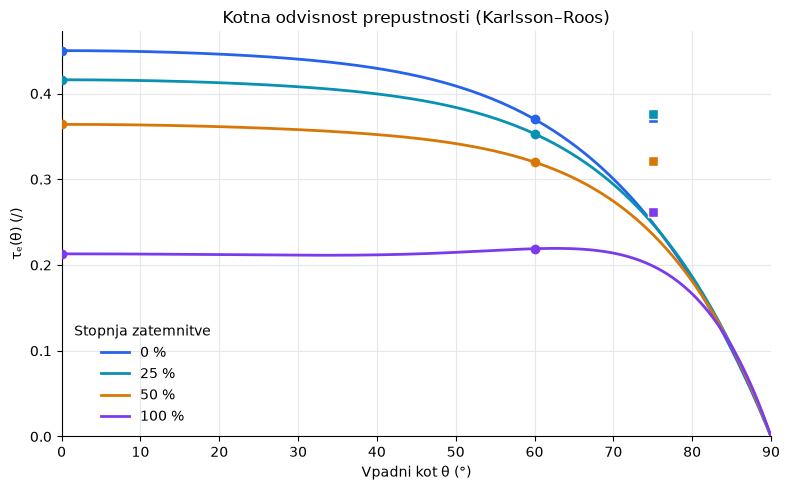

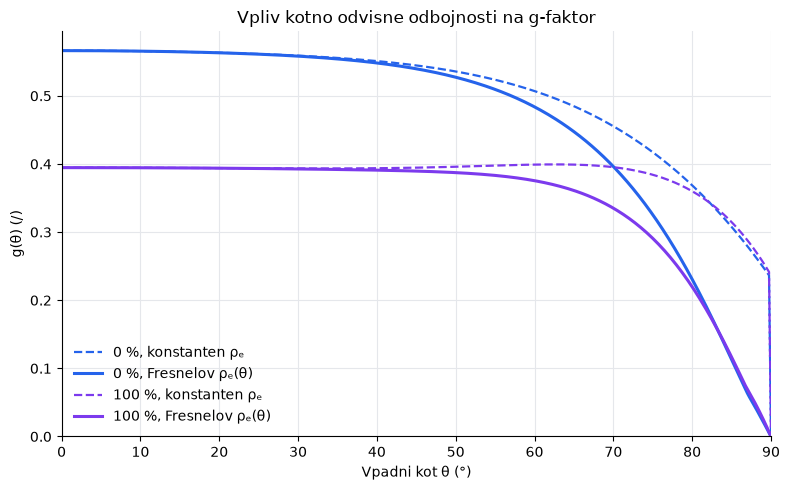

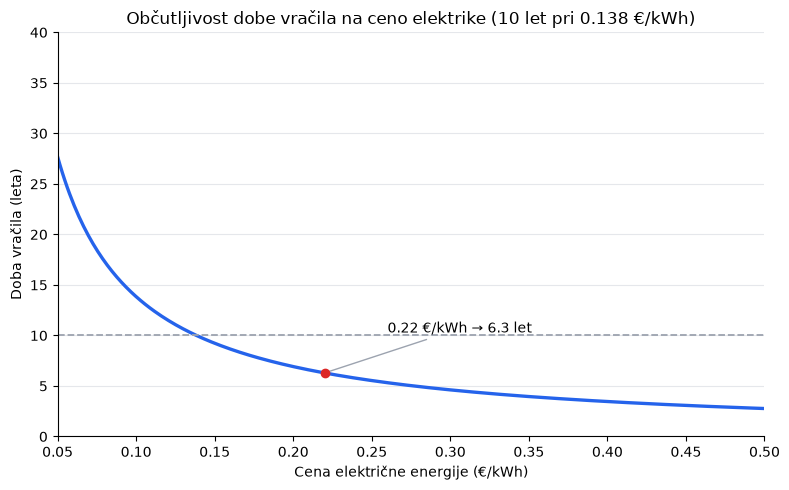

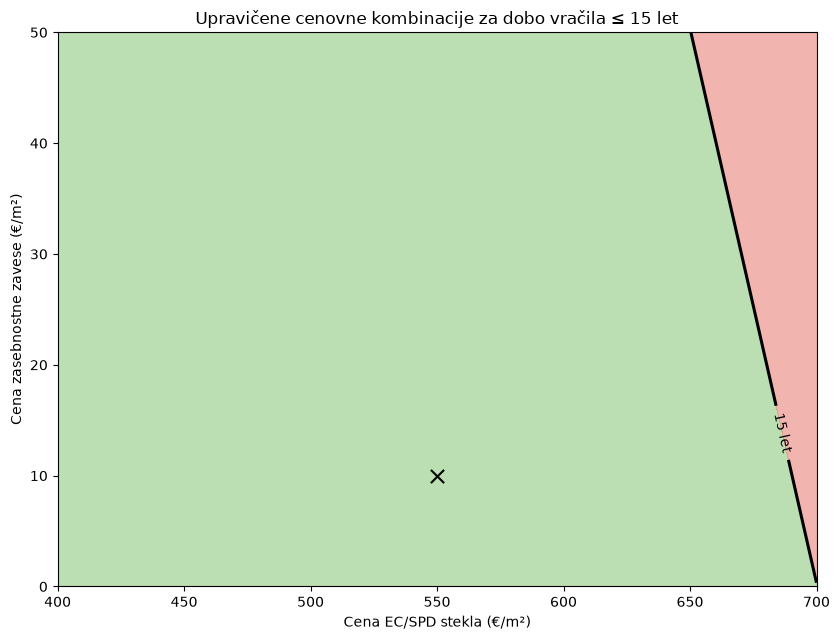

In [43]:
R, sched = run_all()
with open(os.path.join(OUTDIR, "rezultati.json"), "w", encoding="utf-8") as fh:
    json.dump(R, fh, ensure_ascii=False, indent=2, default=float)

print("q (kalibracija iz tau(%d) / tau(0)):" % THETA_CAL, {s: round(R["q"][s], 2) for s in STATES})
print("tau_dif:", {s: round(R["tau_dif"][s], 3) for s in STATES})
print("g(0 deg):", {s: round(R["g_direct_0"][s], 3) for s in STATES})
if "validation" in R:
    print("\nValidacija pri %d deg:" % R["validation"]["angle"])
    for s, r in R["validation"]["rows"].items():
        print(f"  {s:>3} %  izmerjeno {r['measured']:.3f}  model {r['model']:.3f}  razlika {r['diff_pct_points']:+.1f} o.t.")
print("\nLetni rezultati (MWh):")
rows = [(f"{s} %", R["fixed"][s]) for s in STATES] + [("navadno steklo", R["ordinary"]), ("SPD krmiljen", R["smart"])]
print(pd.DataFrame({n: {k: v for k, v in d.items() if k.endswith("MWh") or k == "cost_eur"} for n, d in rows}).round(1).T)
print(f"\nNeto prihranek: {R['net_savings_eur']:,.0f} EUR/leto | dodatna investicija: {R['investment_extra_eur']:,.0f} EUR")
print(f"DOBA VRACILA: {R['payback_years']:.2f} let")
print("\nMesanice:"); print(pd.DataFrame({k: {"solar_MWh": v["solar_MWh"], "prihranek_EUR": v["net_savings_eur"], "doba_vracila_leta": v["payback_years"]} for k, v in R["mix"].items()}).T.round(2))
print("\nCena SPD stekla:"); print(pd.DataFrame(R["prices"]).round(2))
print("\nCena elektrike:"); print(pd.DataFrame(R["el_price"]).round(2))
print("\nMejna cena SPD stekla (EUR/m2) za dobo vracila <= T let:", {k: round(v) for k, v in R["breakeven_spd_price"].items()})
make_plots(R)